In [ ]:
import pandas as pd
import numpy as np

- dim (dimension): informasi/atribut tambahan
- fact : log/catatan historis (bisa transaksi, bisa event, dll)

In [ ]:
dim_campaign = pd.read_csv('dim_campaign_hands_on.csv')

dim_campaign.head()

,campaign_id,name,start_date,end_date,ad_id,ad_platform,ad_type,target_gender,target_age_group,budget
0,5,Campaign_5_Launch,2025-07-11,2025-08-28,50,Instagram,Stories,Female,35-44,22254.551562
1,5,Campaign_5_Launch,2025-07-11,2025-08-28,179,Instagram,Stories,All,35-44,23276.033023
2,5,Campaign_5_Launch,2025-07-11,2025-08-28,193,Instagram,Carousel,All,25-34,22846.105415
3,13,Campaign_13_Winter,2025-04-19,2025-07-01,8,Facebook,Carousel,All,25-34,3736.625551
4,13,Campaign_13_Winter,2025-04-19,2025-07-01,53,Facebook,Stories,Female,25-34,3482.708948


In [ ]:
fact_ads = pd.read_csv('fact_ads_event_hands_on.csv')

fact_ads.head()

,event_id,ad_id,user_id,timestamp,day_of_week,time_of_day,event_type,purchase_revenue,user_gender,age_group
0,279721,1,00067,2025-06-09 17:55:06.000000000,Monday,Afternoon,Impression,NaN,Male,35-44
1,395144,1,0023e,2025-05-20 06:56:05.000000000,Tuesday,Morning,Impression,NaN,Female,35-44
2,32071,1,00336,2025-08-01 04:25:54.000000000,Friday,Night,Impression,NaN,Female,25-34
3,169314,1,004a5,2025-05-19 14:17:55.000000000,Monday,Afternoon,Impression,NaN,Male,25-34
4,249669,1,00b03,2025-07-30 04:56:44.000000000,Wednesday,Night,Impression,NaN,Female,16-17


# Data Preprocessing

- convert proper date type

In [ ]:
fact_ads['timestamp'] = pd.to_datetime(fact_ads['timestamp'] )

fact_ads.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96939 entries, 0 to 96938
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   event_id          96939 non-null  int64         
 1   ad_id             96939 non-null  int64         
 2   user_id           96939 non-null  object        
 3   timestamp         96939 non-null  datetime64[ns]
 4   day_of_week       96939 non-null  object        
 5   time_of_day       96939 non-null  object        
 6   event_type        96939 non-null  object        
 7   purchase_revenue  435 non-null    float64       
 8   user_gender       96939 non-null  object        
 9   age_group         96939 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(6)
memory usage: 7.4+ MB


# Analysis

## Funnel Analysis

Melihat funnel / proporsi user di masing-masing tahapan journey customer dari awareness (impression) sampai action (purchase)

In [ ]:
fact_ads.value_counts('event_type')

,count
event_type,
Impression,83229
Click,9224
Like,2698
Comment,928
Purchase,435
Share,425


In [ ]:
# Filter Event
fact_funnel = fact_ads[ fact_ads['event_type'].isin(['Impression', 'Click', 'Purchase']) ].copy()

# Set Categories, agar saat analisis & visualisasi funnelnya urut
fact_funnel['event_type'] = pd.Categorical(
    fact_funnel['event_type'],
    categories = ['Impression', 'Click', 'Purchase'],
    ordered = True
)

fact_funnel.info()

<class 'pandas.core.frame.DataFrame'>
Index: 92888 entries, 0 to 96938
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   event_id          92888 non-null  int64         
 1   ad_id             92888 non-null  int64         
 2   user_id           92888 non-null  object        
 3   timestamp         92888 non-null  datetime64[ns]
 4   day_of_week       92888 non-null  object        
 5   time_of_day       92888 non-null  object        
 6   event_type        92888 non-null  category      
 7   purchase_revenue  435 non-null    float64       
 8   user_gender       92888 non-null  object        
 9   age_group         92888 non-null  object        
dtypes: category(1), datetime64[ns](1), float64(1), int64(2), object(5)
memory usage: 7.2+ MB


In [ ]:
# Merge fact funnel to dim_campaign to get relevant info
fact_funnel = fact_funnel.merge(dim_campaign[['campaign_id',
                                              'name',
                                              'ad_id',
                                              'ad_type',
                                              'ad_platform']],
                                on = 'ad_id')

fact_funnel

,event_id,ad_id,user_id,timestamp,day_of_week,time_of_day,event_type,purchase_revenue,user_gender,age_group,campaign_id,name,ad_type,ad_platform
0,279721,1,00067,2025-06-09 17:55:06.000000000,Monday,Afternoon,Impression,NaN,Male,35-44,28,Campaign_28_Winter,Video,Facebook
1,395144,1,0023e,2025-05-20 06:56:05.000000000,Tuesday,Morning,Impression,NaN,Female,35-44,28,Campaign_28_Winter,Video,Facebook
2,32071,1,00336,2025-08-01 04:25:54.000000000,Friday,Night,Impression,NaN,Female,25-34,28,Campaign_28_Winter,Video,Facebook
3,169314,1,004a5,2025-05-19 14:17:55.000000000,Monday,Afternoon,Impression,NaN,Male,25-34,28,Campaign_28_Winter,Video,Facebook
4,249669,1,00b03,2025-07-30 04:56:44.000000000,Wednesday,Night,Impression,NaN,Female,16-17,28,Campaign_28_Winter,Video,Facebook
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92883,208758,193,ff718,2025-05-11 15:02:03.000000000,Sunday,Afternoon,Click,NaN,Female,25-34,5,Campaign_5_Launch,Carousel,Instagram
92884,408858,193,ff718,2025-05-19 04:30:36.748244620,Sunday,Afternoon,Impression,NaN,Female,25-34,5,Campaign_5_Launch,Carousel,Instagram
92885,175710,193,ffa8e,2025-06-02 03:51:34.000000000,Monday,Night,Impression,NaN,Male,35-44,5,Campaign_5_Launch,Carousel,Instagram
92886,155300,193,ffd56,2025-06-07 08:58:53.000000000,Saturday,Morning,Impression,NaN,Male,25-34,5,Campaign_5_Launch,Carousel,Instagram


### Visualisasi

In [ ]:
agg_funnel = (
    fact_funnel
    .groupby(['event_type'], observed = True)['user_id']
    .nunique()
    .sort_index()
)

agg_funnel = agg_funnel.to_frame('count')

agg_funnel['percent'] = (
    agg_funnel['count']
    / agg_funnel['count'].shift(1)
    * 100
)

agg_funnel.fillna(100, inplace =True)

agg_funnel

,count,percent
event_type,,
Impression,9947,100.000000
Click,5993,60.249321
Purchase,424,7.074921


- Dari 9947 unique user yang melihat iklan, ada 5993 (60%) yang click
- Dari 5993 unique user yang click iklannya, ada 424 (7%) yang purchase
- Funnel drop-off: penurunan % terbesar -> di tahapan click ke purchase (sebelumnya 60% langsung turun ke 7%)

Funnel drop-off membantu menganalisis tahapan funnel mana yang kurang bagus performanya agar bisa dievaluasi lebih mendalam

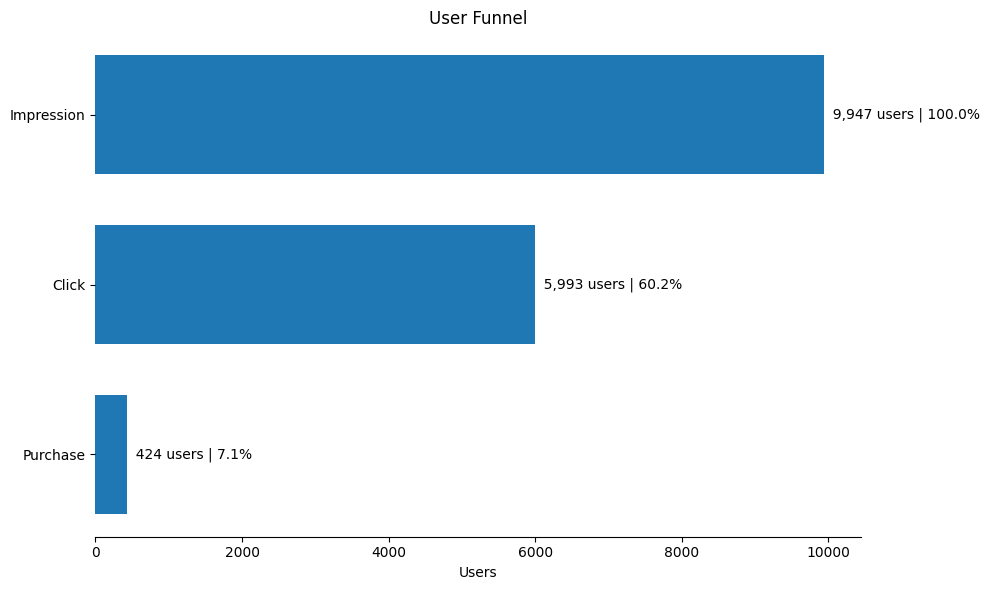

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

# Funnel bars
ax.barh(
    agg_funnel.index,
    agg_funnel['count'],
    height=0.7
)

# Add count + conversion percentage
for i, (count, pct) in enumerate(
    zip(agg_funnel['count'], agg_funnel['percent'])
):
    ax.text(
        count,
        i,
        f'  {count:,} users | {pct:.1f}%',
        va='center',
        fontsize=10
    )

ax.invert_yaxis()

ax.set_title('User Funnel')
ax.set_xlabel('Users')
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
plt.show()

## Campaign Analysis

- CTR (Click-Through Rate): Click / Impression
- CVR / CR (Conversion Rate): Purchase / Click

Evaluasi campaign sesuai funnel
- Fokus ke meningkatkan awareness --> cari impression tertingg
- Fokus ke interest/desire --> cari CTR tertinggi
- Fokus ke conversion/action --> cari CVR tertinggi

In [ ]:
campaign_funnel = (
    fact_funnel.
    groupby(['campaign_id', 'name',  'event_type'], observed=True)['user_id'].
    nunique().
    unstack(fill_value = 0)
)

campaign_funnel['CTR'] = campaign_funnel['Click'] / campaign_funnel['Impression']
campaign_funnel['CVR'] = campaign_funnel['Purchase'] / campaign_funnel['Click']

campaign_funnel.sort_values('CTR', ascending = False)

,event_type,Impression,Click,Purchase,CTR,CVR
campaign_id,name,,,,,
42,Campaign_42_Summer,7814,1523,66,0.194907,0.043336
29,Campaign_29_Winter,7340,1398,58,0.190463,0.041488
13,Campaign_13_Winter,6830,1192,64,0.174524,0.053691
21,Campaign_21_Winter,5251,833,49,0.158636,0.058824
46,Campaign_46_Winter,6116,955,36,0.156148,0.037696
39,Campaign_39_Q3,4378,649,26,0.148241,0.040062
28,Campaign_28_Winter,4382,620,30,0.141488,0.048387
5,Campaign_5_Launch,4363,599,34,0.137291,0.056761
27,Campaign_27_Q3,3131,420,33,0.134142,0.078571


In [ ]:
campaign_funnel.sort_values('CTR', ascending=False).style \
    .background_gradient(
        cmap='Blues',
        subset=['Impression']
    ) \
    .background_gradient(
        cmap='Greens',
        subset=['CTR']
    ) \
    .background_gradient(
        cmap='Oranges',
        subset=['CVR']
    ) \
    .format({
        # 'Impression': '{:,.0f}',
        'Impression': lambda x: f'{x / 1_000:.1f}K',
        'CTR': '{:.1%}',
        'CVR': '{:.1%}'
    })

,event_type,Impression,Click,Purchase,CTR,CVR
campaign_id,name,,,,,
42,Campaign_42_Summer,7.8K,1523,66,19.5%,4.3%
29,Campaign_29_Winter,7.3K,1398,58,19.0%,4.1%
13,Campaign_13_Winter,6.8K,1192,64,17.5%,5.4%
21,Campaign_21_Winter,5.3K,833,49,15.9%,5.9%
46,Campaign_46_Winter,6.1K,955,36,15.6%,3.8%
39,Campaign_39_Q3,4.4K,649,26,14.8%,4.0%
28,Campaign_28_Winter,4.4K,620,30,14.1%,4.8%
5,Campaign_5_Launch,4.4K,599,34,13.7%,5.7%
27,Campaign_27_Q3,3.1K,420,33,13.4%,7.9%


**Exercise**

Analisis jenis konten (ad_type & ad_platform) mana yang:

- menghasilkan impression tertinggi
- menghasilkan CTR tertinggi
- menghasilkan CVR tertinggi

Buat table heatmap seperti di atas

beri nama tablenya `content_funnel`

In [ ]:
content_funnel = (
    fact_funnel.
    groupby(['ad_platform', 'ad_type',  'event_type'], observed=True)['user_id'].
    nunique().
    unstack(fill_value = 0)
)

content_funnel['CTR'] = content_funnel['Click'] / content_funnel['Impression']
content_funnel['CVR'] = content_funnel['Purchase'] / content_funnel['Click']

content_funnel.sort_values('CTR', ascending = False)

event_type            Impression  Click  Purchase       CTR       CVR
ad_platform ad_type                                                  
Facebook    Stories         8519   1918        95  0.225144  0.049531
Instagram   Stories         7822   1525        84  0.194963  0.055082
Facebook    Image           7353   1321        67  0.179655  0.050719
Instagram   Carousel        6774   1180        57  0.174195  0.048305
Facebook    Video           6137   1012        51  0.164901  0.050395
            Carousel        6061    988        50  0.163009  0.050607
Instagram   Image           3170    432        19  0.136278  0.043981
            Video           1771    205        10  0.115754  0.048780

In [ ]:
content_funnel.sort_values('CTR', ascending=False).style \
    .background_gradient(
        cmap='Blues',
        subset=['Impression']
    ) \
    .background_gradient(
        cmap='Greens',
        subset=['CTR']
    ) \
    .background_gradient(
        cmap='Oranges',
        subset=['CVR']
    ) \
    .format({
        # 'Impression': '{:,.0f}',
        'Impression': lambda x: f'{x / 1_000:.1f}K',
        'CTR': '{:.1%}',
        'CVR': '{:.1%}'
    })

## Revenue & Cost Analysis

- CPM (Cost per Mille): Cost / Impression * 1000
- CPC (Cost per Click): Cost / Click
- CPA (Cost per Acquisition): Cost / Purchase
- ROAS (Return on Ads SPend): Revenue / Cost

In [ ]:
campaign_funnel.head()

,event_type,Impression,Click,Purchase,CTR,CVR
campaign_id,name,,,,,
5,Campaign_5_Launch,4363,599,34,0.137291,0.056761
13,Campaign_13_Winter,6830,1192,64,0.174524,0.053691
21,Campaign_21_Winter,5251,833,49,0.158636,0.058824
26,Campaign_26_Winter,4377,587,37,0.134110,0.063032
27,Campaign_27_Q3,3131,420,33,0.134142,0.078571


In [ ]:
# Total revenue dari masing-masing campaign_id
campaign_funnel_revenue = fact_funnel.groupby(['campaign_id']).agg(
    revenue = ('purchase_revenue', 'sum')
)

# Total cost (budget) iklan dari masing-masing campaign_id
campaign_funnel_budget= dim_campaign.groupby('campaign_id').agg(
    total_cost = ('budget', 'sum')
)

campaign_funnel_2 = campaign_funnel.\
  merge(campaign_funnel_revenue, on = 'campaign_id', how ='left').\
  merge(campaign_funnel_budget, on = 'campaign_id', how = 'left')

# Metrics on cost & profitability
campaign_funnel_2['CPM'] = campaign_funnel_2['total_cost'] / campaign_funnel_2['Impression'] * 1000
campaign_funnel_2['CPC'] = campaign_funnel_2['total_cost'] / campaign_funnel_2['Click']
campaign_funnel_2['CPA'] = campaign_funnel_2['total_cost'] / campaign_funnel_2['Purchase']
campaign_funnel_2['ROAS'] = campaign_funnel_2['revenue'] / campaign_funnel_2['total_cost']

campaign_funnel_2

,campaign_id,name,Impression,Click,Purchase,CTR,CVR,revenue,total_cost,CPM,CPC,CPA,ROAS
0,5,Campaign_5_Launch,4363,599,34,0.137291,0.056761,51357.767628,68376.69,15671.943617,114.151402,2011.079118,0.751101
1,13,Campaign_13_Winter,6830,1192,64,0.174524,0.053691,86905.613608,21855.42,3199.915081,18.335084,341.490937,3.976387
2,21,Campaign_21_Winter,5251,833,49,0.158636,0.058824,80337.097954,37290.81,7101.658732,44.766879,761.036939,2.154340
3,26,Campaign_26_Winter,4377,587,37,0.134110,0.063032,52633.832922,44538.87,10175.661412,75.875417,1203.753243,1.181751
4,27,Campaign_27_Q3,3131,420,33,0.134142,0.078571,58029.091702,12986.30,4147.652507,30.919762,393.524242,4.468485
5,28,Campaign_28_Winter,4382,620,30,0.141488,0.048387,50489.271022,32844.79,7495.387951,52.975468,1094.826333,1.537208
6,29,Campaign_29_Winter,7340,1398,58,0.190463,0.041488,105022.437667,19773.66,2693.959128,14.144249,340.925172,5.311229
7,39,Campaign_39_Q3,4378,649,26,0.148241,0.040062,39994.753315,55638.18,12708.583828,85.729091,2139.930000,0.718836
8,42,Campaign_42_Summer,7814,1523,66,0.194907,0.043336,96343.510908,7918.04,1013.314564,5.198976,119.970303,12.167596
9,46,Campaign_46_Winter,6116,955,36,0.156148,0.037696,42419.808711,94023.76,15373.407456,98.454199,2611.771111,0.451161


In [ ]:
campaign_funnel_2.\
    sort_values('ROAS', ascending=False).style \
    .background_gradient(
        cmap='Blues',
        subset=['Impression', 'CPM']
    ) \
    .background_gradient(
        cmap='Greens',
        subset=['CVR', 'CPA', 'ROAS']
    ) \
    .background_gradient(
        cmap='Oranges',
        subset=['CTR', 'CPC']
    ) \
    .format({
        # 'Impression': '{:,.0f}',
        'Impression': lambda x: f'{x / 1_000:.1f}K',
        'CTR': '{:.1%}',
        'CVR': '{:.1%}',
        'revenue': lambda x: f'{x / 1_000:.1f}K',
        'total_cost': lambda x: f'{x / 1_000:.1f}K',
        'CPM': '{:,.1f}',
        'CPC': '{:,.1f}',
        'CPA': '{:,.1f}',
        'ROAS': '{:.1f}'
    })


,campaign_id,name,Impression,Click,Purchase,CTR,CVR,revenue,total_cost,CPM,CPC,CPA,ROAS
8,42,Campaign_42_Summer,7.8K,1523,66,19.5%,4.3%,96.3K,7.9K,"1,013.3",5.2,120.0,12.2
6,29,Campaign_29_Winter,7.3K,1398,58,19.0%,4.1%,105.0K,19.8K,"2,694.0",14.1,340.9,5.3
4,27,Campaign_27_Q3,3.1K,420,33,13.4%,7.9%,58.0K,13.0K,"4,147.7",30.9,393.5,4.5
1,13,Campaign_13_Winter,6.8K,1192,64,17.5%,5.4%,86.9K,21.9K,"3,199.9",18.3,341.5,4.0
2,21,Campaign_21_Winter,5.3K,833,49,15.9%,5.9%,80.3K,37.3K,"7,101.7",44.8,761.0,2.2
5,28,Campaign_28_Winter,4.4K,620,30,14.1%,4.8%,50.5K,32.8K,"7,495.4",53.0,"1,094.8",1.5
3,26,Campaign_26_Winter,4.4K,587,37,13.4%,6.3%,52.6K,44.5K,"10,175.7",75.9,"1,203.8",1.2
0,5,Campaign_5_Launch,4.4K,599,34,13.7%,5.7%,51.4K,68.4K,"15,671.9",114.2,"2,011.1",0.8
7,39,Campaign_39_Q3,4.4K,649,26,14.8%,4.0%,40.0K,55.6K,"12,708.6",85.7,"2,139.9",0.7
9,46,Campaign_46_Winter,6.1K,955,36,15.6%,3.8%,42.4K,94.0K,"15,373.4",98.5,"2,611.8",0.5



- CPM (Cost per Mille): Cost per 1,000 Impression. Semakin kecil, maka ongkos untuk meningkatkan impression (awareness) lebih murah

- CPC (Cost per Click): semakin kecil nilainya, maka ongkos untuk meningkatkan engagement (interest/desire) lebih murah

- CPA (Cost per Acquisition): semkain kecil nilainya, maka ongkos untuk meningkatkan action/conversion lebih murah

- ROAS (Return on Ads Spend): Untuk setiap dollar/cost yang dikeluarkan, berapa kali lipat revenue yang dihasilkan.

   * Semakin besar = semakin untung
   * ROAS = 1 = impas (cost = revenue)
   * ROAS < 1 = rugi (cost > revenue)

**Exercise**

Evaluasi CPM, CPC, CPA, dan ROAS dari masing-masing jenis konten (ad_type & ad_platform)

In [ ]:
content_funnel = (
    fact_funnel.
    groupby(['ad_platform', 'ad_type',  'event_type'], observed=True)['user_id'].
    nunique().
    unstack(fill_value = 0)
).reset_index()

content_funnel['CTR'] = content_funnel['Click'] / content_funnel['Impression']
content_funnel['CVR'] = content_funnel['Purchase'] / content_funnel['Click']

# Total revenue dari masing-masing ad_type & ad_platform
content_funnel_revenue = fact_funnel.groupby(['ad_type', 'ad_platform']).agg(
    revenue = ('purchase_revenue', 'sum')
)

# Total cost (budget) iklan dari masing-masing ad_type & ad_platform
content_funnel_budget= dim_campaign.groupby(['ad_type', 'ad_platform']).agg(
    total_cost = ('budget', 'sum'),
    n_ads = ('ad_id', 'nunique')
)

content_funnel_2 = content_funnel.\
  merge(content_funnel_revenue, on = ['ad_type', 'ad_platform'], how ='left').\
  merge(content_funnel_budget, on = ['ad_type', 'ad_platform'], how = 'left')

# Metrics on cost & profitability
content_funnel_2['CPM'] = content_funnel_2['total_cost'] / content_funnel_2['Impression'] * 1000
content_funnel_2['CPC'] = content_funnel_2['total_cost'] / content_funnel_2['Click']
content_funnel_2['CPA'] = content_funnel_2['total_cost'] / content_funnel_2['Purchase']
content_funnel_2['ROAS'] = content_funnel_2['revenue'] / content_funnel_2['total_cost']
content_funnel_2['ARPPU'] = content_funnel_2['revenue'] / content_funnel_2['Purchase']

content_funnel_2.\
    sort_values('ROAS', ascending=False).style \
    .background_gradient(
        cmap='Blues',
        subset=['Impression', 'CPM']
    ) \
    .background_gradient(
        cmap='Greens',
        subset=['CVR', 'CPA', 'ROAS']
    ) \
    .background_gradient(
        cmap='Oranges',
        subset=['CTR', 'CPC']
    ) \
    .format({
        # 'Impression': '{:,.0f}',
        'Impression': lambda x: f'{x / 1_000:.1f}K',
        'CTR': '{:.1%}',
        'CVR': '{:.1%}',
        'revenue': lambda x: f'{x / 1_000:.1f}K',
        'total_cost': lambda x: f'{x / 1_000:.1f}K',
        'ARPPU': lambda x: f'{x / 1_000:.1f}K',
        'CPM': '{:,.1f}',
        'CPC': '{:,.1f}',
        'CPA': '{:,.1f}',
        'ROAS': '{:.1f}'
    })


,ad_platform,ad_type,Impression,Click,Purchase,CTR,CVR,revenue,total_cost,n_ads,CPM,CPC,CPA,ROAS,ARPPU
7,Instagram,Video,1.8K,205,10,11.6%,4.9%,15.4K,4.0K,1,"2,235.4",19.3,395.9,3.9,1.5K
2,Facebook,Stories,8.5K,1918,95,22.5%,5.0%,162.7K,70.0K,10,"8,218.6",36.5,737.0,2.3,1.7K
3,Facebook,Video,6.1K,1012,51,16.5%,5.0%,83.3K,36.2K,5,"5,904.3",35.8,710.5,2.3,1.6K
5,Instagram,Image,3.2K,432,19,13.6%,4.4%,22.7K,11.4K,2,"3,598.4",26.4,600.4,2.0,1.2K
0,Facebook,Carousel,6.1K,988,50,16.3%,5.1%,58.0K,31.4K,5,"5,176.7",31.8,627.5,1.8,1.2K
6,Instagram,Stories,7.8K,1525,84,19.5%,5.5%,130.5K,79.3K,8,"10,138.8",52.0,944.1,1.6,1.6K
1,Facebook,Image,7.4K,1321,67,18.0%,5.1%,101.0K,85.6K,7,"11,642.6",64.8,"1,277.7",1.2,1.5K
4,Instagram,Carousel,6.8K,1180,57,17.4%,4.8%,90.0K,77.3K,6,"11,417.5",65.5,"1,356.9",1.2,1.6K


ROAS tertinggi -> Instagram + Video, meskipun CVR bukan yang tertinggi, tapi paling profitable

ARPPU --> average revenue per purchasing user, dari yang melakukan purchase, rata-rata spendingnya berapa

Kalau dibandingkan antar konten, tidak terlalu banyak perbedaan dari sisi ARPPU, artinya spending antar customer tidak akan berbeda jika belanja dari instagram maupun dari facebook, sehingga perbedaan revenue terutama berasal dari kemampuan konten menghasilkan volume purchase. Sementara itu, perbedaan ROAS yang cukup besar lebih banyak terlihat dari perbedaan acquisition cost/CPA.
